# Linear Regression to Predict Titanic Passenger Age

**Deep Dive Coding Data Science Bootcamp Sample Project**

---
Robert Citek - October 5th, 2026


## Problem Definition

State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.

### Regression

For a regression, the Age will be the target.


## Data Collection/Sources

### Data Overview

This data comes from [Kaggle](https://www.kaggle.com/c/titanic/data), which was then copied to AWS for easy access.

https://ddc-datascience.s3.amazonaws.com/Projects/Example/Data/Titanic.train.csv


### Imports

In [6]:
from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

### File Paths

Create a variable `url` that contains the web link to the CSV data

In [7]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Example/Data/Titanic.train.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Example/Data/Titanic.train.csv'

### Load data

Load the data into a data frame named `titanic_df`.

In [8]:
# load data
titanic_df= pd.read_csv(url)

### head

Look at the first few rows

In [9]:
# first few rows
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### tail

Look at the last few rows


In [10]:
# last few rows
titanic_df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


### shape


In [11]:
# shape of data frame
titanic_df.shape

(891, 12)

### size


In [12]:
# size of data frame
titanic_df.size

10692

### Summary meta-data

Run the `info()` method on the data frame.


In [13]:
# display meta-data
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### Summary statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

Run the `describe()` method on the data frame.

In [14]:
# display summary statistics
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### target nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [15]:
# look for nulls in the target
titanic_df['Survived'].value_counts(dropna=False)

,count
Survived,
0,549
1,342


### Nulls



In [16]:
# look for nulls
titanic_df.isnull().sum().sort_values(ascending=False)

,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


In [17]:
# look for nulls, displaying relative frequency
null_sum= titanic_df.isnull().sum()
null_freq= null_sum/titanic_df.shape[0]*100
null_freq.sort_values()

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000
Embarked,0.224467


### dtypes - column data types

Which data types would be appropriate for Linear Regression?


In [18]:
# display data types
titanic_df.dtypes.sort_values()

,0
PassengerId,int64
Survived,int64
Pclass,int64
SibSp,int64
Parch,int64
Age,float64
Fare,float64
Name,object
Sex,object
Ticket,object


### Unique elements


If the total number of unique items in a field equals the number of rows, that suggests those fields are unique IDs ( e.g. names, IDs ) and should be dropped.


In [19]:
# number of unique elements in a column
titanic_df.nunique().sort_values(ascending=False)

,0
PassengerId,891
Name,891
Ticket,681
Fare,248
Cabin,147
Age,88
SibSp,7
Parch,7
Embarked,3
Pclass,3


## Data Cleaning


### Backup #1


In [20]:
# make backup
titanic_df_backup= titanic_df.copy()

In [21]:
# restore from backup
titanic_df = titanic_df_backup.copy()

### Keep only the target and two features

Select `Age` for the target and `Fare` for the feature

In [22]:
# select the target and one feature
titanic_df_age_fare = titanic_df[['Age','Fare']]
titanic_df_age_fare.head()

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


### Backup #2


In [23]:
# make backup
titanic_df_age_fare_backup = titanic_df_age_fare.copy()

In [24]:
# restore from backup
titanic_df_age_fare_backup = titanic_df_age_fare_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.


#### Impute

In [25]:
# counts the nulls in age and fare
titanic_df_age_fare.isnull().sum().sort_values (ascending=False)

,0
Age,177
Fare,0


In [26]:
# drop the nulls values in Age
titanic_df_age_fare = titanic_df_age_fare.dropna(subset=['Age'])

In [27]:
# verify nulls values in Age
titanic_df_age_fare.isnull().sum()

,0
Age,0
Fare,0


Impute with the median.


In [28]:
# Calculate the median


In [29]:
# Assign median to nulls


In [30]:
# Verify there are no nulls


In [31]:
# Verify median is about the same as before


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

### correlated with the target


In [32]:
# Calculate a correlation matrix for the target
titanic_df_age_fare.corr() ;

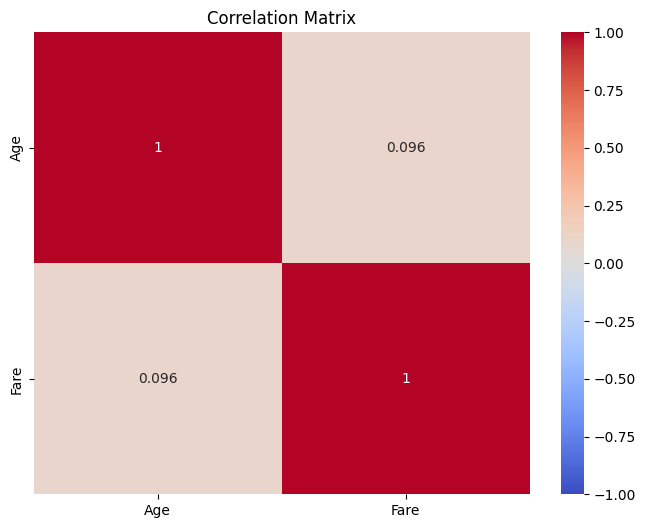

In [77]:
# Display the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(titanic_df_age_fare.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()

In [34]:
# Create a data series with features ranked by correlation


### independence of features: correlation

In [35]:
# Calculate a correlation matrix for the features


In [36]:
# Display the correlation matrix


In [37]:
# Create a data series with features ranked by correlation


## Processing

### Prepare data frame

In [48]:
# Split data frame into target and features
x = titanic_df_age_fare[['Fare']] # x= is the features
y = titanic_df_age_fare['Age']    # y= is for target


In [50]:
# Verify features
x.shape

(714, 1)

In [51]:
# Verify target
y.shape

(714,)

In [52]:
# Create the model using Sklearn
model= LinearRegression()


#option 2, not sure why
#myfit2= model.fit(x_train,y_train)
#( myfit2.intercept_, myfit2.coef_ )

### Multiple Cross Validation ( CV )

Create a CV loop with 100 iterations.  Capture performance metric in an array names `results`.
Use accuracy for the performance metric.


In [72]:
# Multiple CV loop

results = []
for i in range(100):
    x_train, x_test, y_train, y_test = train_test_split( x , y, test_size = 0.2, )
    model= LinearRegression()
    model.fit(x_train, y_train) #
    y_pred = model.predict(x_test)
    rmse = metrics.mean_squared_error(y_test, y_pred) ** 0.5   # RMSE for this split
    results.append (rmse) # this save the calculation in the list results

results = np.array(results)





In [73]:
results

array([14.84862039, 14.14074705, 13.23839798, 14.63375804, 14.08585382,
       13.81288486, 13.33922426, 13.80986716, 14.50375071, 14.96226902,
       14.92849871, 14.21824128, 14.01384858, 15.49714466, 14.98856491,
       14.56206982, 14.24945132, 13.62297903, 13.88668019, 14.72879489,
       14.18238142, 13.72893569, 14.87641294, 13.07321857, 14.74558515,
       13.86611781, 14.21803898, 14.05511675, 15.10214061, 14.55834372,
       15.00022968, 15.19733015, 12.52481977, 14.0969128 , 13.93632205,
       13.75674108, 15.41522898, 14.4237644 , 14.96645907, 14.94579315,
       14.50107965, 15.16992941, 14.89252901, 14.10445312, 14.36231859,
       13.7378324 , 15.34667412, 14.87220725, 14.03011341, 13.3632021 ,
       13.87454437, 15.14424468, 15.56778183, 14.63764496, 13.82439185,
       13.39688994, 14.44202111, 15.10754062, 14.3763981 , 13.79720196,
       13.5976417 , 15.74841837, 13.69835735, 13.25063106, 14.60426511,
       14.75026726, 13.65439554, 14.09101052, 14.24114133, 13.81

#### Performance

We'll use RMSE as our performance metric.

In [74]:
# Calculate mean of results

rmse = results.mean()
print(f"RMSE: {rmse}")




RMSE: 14.447154697924313


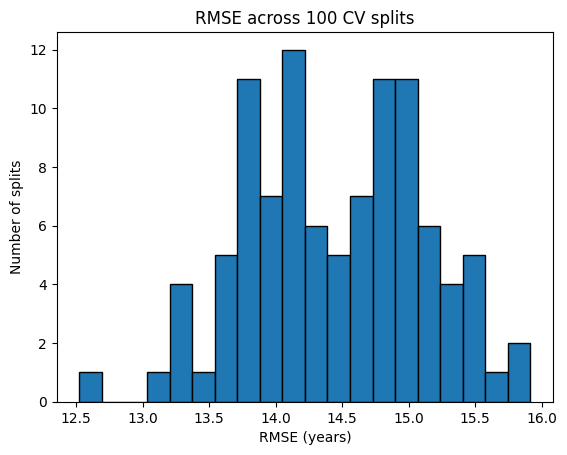

In [75]:
# Display a histogram of the results
plt.hist(results, bins=20, edgecolor='black')
plt.xlabel('RMSE (years)')
plt.ylabel('Number of splits')
plt.title('RMSE across 100 CV splits')
plt.show()

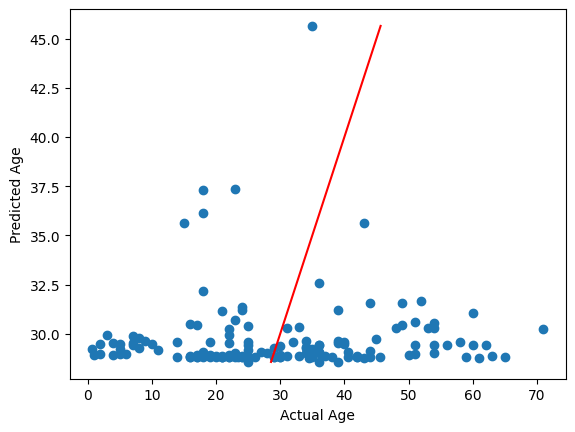

In [76]:
# See how well our model performs on our test data

y_pred = model.predict(x_test)
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)],[min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Age')
plt.ylabel('Predicted Age') ;

## Communication of Results

Conclusion:

Future work:


